# NLP Lab Assignment 10: Word embeddings (Word2Vec, GloVe, FastText)
**AI357 · Natural Language Processing, SVNIT Surat**

1. **Q1:** Preprocess Amazon reviews, take stratified samples (10,000 train and 1,000 test), and build sentence vectors with all three embedding models.
2. **Q2:** Solve word analogies (`good − bad + excellent`, `delivery − late + fast`) and measure each model's accuracy on Mikolov's `questions-words.txt`.
3. **Q3:** Train a single-hidden-layer neural network per embedding, once on **mean** sentence vectors and once on **TF-IDF-weighted mean** vectors, then compare macro F1.

**Data and models.** Run `python download_data.py` first. It fetches these files into `raw_data/`:

| Resource | Source used | Note |
|---|---|---|
| Amazon reviews | HF `fancyzhx/amazon_polarity` | Same Zhang et al. (2015) Amazon polarity corpus as Kaggle `kritanjalijain/amazon-reviews` (3.6M train / 400k test). The Kaggle copy needs an API token. |
| Word2Vec | HF `fse/word2vec-google-news-300` | The link in the assignment. 3M words, 300d. |
| GloVe | HF `fse/glove-wiki-gigaword-300` | GloVe 6B 300d (Wikipedia + Gigaword), 400k lowercase words. |
| FastText | HF `fse/fasttext-wiki-news-subwords-300` | `wiki-news-300d-1M-subword.vec` from fasttext.cc, saved in gensim format. 1M words, 300d. |
| Analogies | `questions-words.txt` (nicholas-leonard/word2vec) | 19,544 questions in 14 sections. |

All three embeddings are stored as gensim `KeyedVectors` and loaded with `mmap='r'`. The 3.6 GB Word2Vec matrix stays on disk and is paged in on demand, so the notebook runs on a machine with little free RAM.

In [1]:
from pathlib import Path
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from gensim.models import KeyedVectors
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)

locations = [Path.cwd(), Path.cwd() / 'Lab-Assignment-10']
ASSIGNMENT_DIR = next((p for p in locations if (p / 'raw_data' / 'amazon').is_dir()), None)
if ASSIGNMENT_DIR is None:
    raise FileNotFoundError('raw_data/ not found: run `python download_data.py` inside Lab-Assignment-10 first')
RAW = ASSIGNMENT_DIR / 'raw_data'
OUT = ASSIGNMENT_DIR / 'outputs'
OUT.mkdir(exist_ok=True)

for resource in ['stopwords', 'punkt_tab']:
    nltk.download(resource, quiet=True)
LABEL_NAMES = {0: 'negative', 1: 'positive'}
print('Assignment directory:', ASSIGNMENT_DIR)

Assignment directory: D:\SEM5\NLP\NLP-LAB\Lab-Assignment-10


## Q1. Load, sample, and preprocess the reviews

### 1.1 Stratified sampling
The training split has 3.6M reviews in four parquet shards. Loading all the review text at once would need several GB. Instead, only the `label` column of every shard is read, `train_test_split(..., stratify=label)` picks 10,000 row ids (1,000 for test), and then each shard's text is read once to pull out only the chosen rows. `label` is 0 = negative and 1 = positive; the Kaggle CSV encodes these as 1 and 2. The `content` column is the review text (the Kaggle `text` column).

In [2]:
def stratified_sample(paths, n, seed=SEED):
    labels = [pq.read_table(p, columns=['label'])['label'].to_numpy() for p in paths]
    y = np.concatenate(labels)
    shard = np.concatenate([np.full(len(l), i) for i, l in enumerate(labels)])
    row = np.concatenate([np.arange(len(l)) for l in labels])
    chosen, _ = train_test_split(np.arange(len(y)), train_size=n, stratify=y, random_state=seed)
    parts = []
    for i, path in enumerate(paths):
        rows = np.sort(row[chosen[shard[chosen] == i]])
        if len(rows):
            parts.append(pq.read_table(path, columns=['label', 'title', 'content']).take(rows).to_pandas())
    sample = pd.concat(parts, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)
    population = pd.Series(y).map(LABEL_NAMES).value_counts(normalize=True)
    return sample, population

train_paths = sorted((RAW / 'amazon').glob('train-*.parquet'))
test_paths = sorted((RAW / 'amazon').glob('test-*.parquet'))
start = time.time()
train_df, train_pop = stratified_sample(train_paths, 10_000)
test_df, test_pop = stratified_sample(test_paths, 1_000)
print(f'Sampled in {time.time() - start:.1f}s: train={len(train_df)}, test={len(test_df)}')

dist = pd.DataFrame({
    'full train': train_pop,
    'train sample': train_df['label'].map(LABEL_NAMES).value_counts(normalize=True),
    'full test': test_pop,
    'test sample': test_df['label'].map(LABEL_NAMES).value_counts(normalize=True),
}).round(4)
dist

Sampled in 8.8s: train=10000, test=1000


,full train,train sample,full test,test sample
positive,0.5,0.5,0.5,0.5
negative,0.5,0.5,0.5,0.5


### 1.2 Preprocessing
The steps follow the assignment:

1. **Lowercase.**
2. **Remove punctuation and numbers.** Every character other than `a–z` and whitespace becomes a space. Contractions are expanded first (`can't → can not`, `don't → do not`), so the negation survives instead of becoming the fragments `don` and `t`.
3. **Tokenize** with NLTK `word_tokenize`.
4. **Remove stopwords** with NLTK's English list. The negation words `no`, `not` and `nor` are kept: they are stopwords for topic tasks, but they flip polarity (`not good`), and this is a sentiment task. One-letter leftovers are dropped as well.

In [3]:
NEGATIONS = {'no', 'not', 'nor'}
STOPWORDS = set(stopwords.words('english')) - NEGATIONS

def preprocess(text):
    text = text.lower()
    text = re.sub(r"\bcan't\b", 'can not', text)
    text = re.sub(r"\bwon't\b", 'will not', text)
    text = re.sub(r"n't\b", ' not', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    return [tok for tok in word_tokenize(text) if tok not in STOPWORDS and len(tok) > 1]

for df in (train_df, test_df):
    df['tokens'] = df['content'].map(preprocess)

example = train_df.loc[0]
print('Original :', example['content'])
print('Tokens   :', example['tokens'])
lengths = train_df['tokens'].map(len)
print(f'\nTokens per train review: mean={lengths.mean():.1f}, median={lengths.median():.0f}, '
      f'min={lengths.min()}, max={lengths.max()}')
print('Train vocabulary size:', len({t for toks in train_df['tokens'] for t in toks}))

train_df[['label', 'title', 'content']].assign(label=train_df['label'].map(LABEL_NAMES)).to_csv(OUT / 'train_sample.csv', index=False)
test_df[['label', 'title', 'content']].assign(label=test_df['label'].map(LABEL_NAMES)).to_csv(OUT / 'test_sample.csv', index=False)
train_df[['label', 'tokens']].head()

Original : I have been using Canna products for a long time, there is nothing better! Biggest, stickies, stinkiest flowers Ive ever grown, use this stuff, you wont be sorry!
Tokens   : ['using', 'canna', 'products', 'long', 'time', 'nothing', 'better', 'biggest', 'stickies', 'stinkiest', 'flowers', 'ive', 'ever', 'grown', 'use', 'stuff', 'wont', 'sorry']

Tokens per train review: mean=37.7, median=33, min=4, max=163
Train vocabulary size: 31964


,label,tokens
0,1,"[using, canna, products, long, time, nothing, better, biggest, stickies, stinkiest, flowers, ive, ever, grown, use, ..."
1,1,"[tried, tested, pregnancies, no, stretch, marks, first, pregnancy, got, th, month, belly, started, itch, like, crazy..."
2,0,"[experience, previous, poster, belt, thin, work, buckle, use, belts, got, not, buy, folks]"
3,1,"[book, easy, read, spent, last, years, managing, people, clients, last, years, managing, family, book, provides, sec..."
4,1,"[beg, differ, reviewers, not, think, chameleon, best, album, first, two, better, one, contain, best, tune, time, fab..."


### 1.3 Load the three embedding models
Each model is memory-mapped. Gensim's `fill_norms()` would compute `np.linalg.norm(vectors, axis=1)` in a single pass, which first allocates a full-size squared copy (3.6 GB for Word2Vec). The norms are therefore computed in chunks and assigned to `kv.norms`.

In [4]:
MODEL_FILES = {
    'Word2Vec': 'word2vec-google-news-300',
    'GloVe': 'glove-wiki-gigaword-300',
    'FastText': 'fasttext-wiki-news-subwords-300',
}

def load_keyed_vectors(name, chunk=200_000):
    kv = KeyedVectors.load(str(RAW / 'embeddings' / f'{name}.model'), mmap='r')
    norms = np.empty(len(kv), dtype=np.float32)
    for s in range(0, len(kv), chunk):
        norms[s:s + chunk] = np.linalg.norm(kv.vectors[s:s + chunk], axis=1)
    kv.norms = norms
    return kv

models = {}
for label, name in MODEL_FILES.items():
    start = time.time()
    models[label] = load_keyed_vectors(name)
    kv = models[label]
    print(f'{label:9s} vocab={len(kv):>9,}  dim={kv.vector_size}  loaded in {time.time() - start:.1f}s')

Word2Vec  vocab=3,000,000  dim=300  loaded in 48.6s


GloVe     vocab=  400,000  dim=300  loaded in 10.7s


FastText  vocab=  999,999  dim=300  loaded in 33.0s


### 1.4 Sentence representations
A review is represented by combining the vectors of its in-vocabulary tokens. Tokens a model does not know are skipped (these `.vec`-style FastText vectors carry no subword n-grams, so FastText cannot build OOV vectors here either). A review with no known tokens gets the zero vector.

* **Mean (Q3a):** the unweighted average of the word vectors.
* **TF-IDF weighted mean (Q3b):** $\mathbf{s} = \sum_w \text{tfidf}(w,s)\,\mathbf{v}_w \big/ \sum_w \text{tfidf}(w,s)$ over words known to both the TF-IDF vocabulary and the embedding. The TF-IDF model (smoothed IDF, sublinear counts off) is **fit on the 10k training reviews only**, so test words never seen in training get no weight. If none of a review's words have a weight, the plain mean is used.

In [5]:
def mean_vectors(token_lists, kv):
    X = np.zeros((len(token_lists), kv.vector_size), dtype=np.float32)
    for i, toks in enumerate(token_lists):
        ids = [kv.key_to_index[t] for t in toks if t in kv.key_to_index]
        if ids:
            X[i] = kv.vectors[ids].mean(axis=0)
    return X

def tfidf_weighted_vectors(T, vocab, kv, fallback):
    E = np.zeros((len(vocab), kv.vector_size), dtype=np.float32)
    known = np.zeros(len(vocab), dtype=np.float32)
    for j, word in enumerate(vocab):
        if word in kv.key_to_index:
            E[j] = kv.vectors[kv.key_to_index[word]]
            known[j] = 1.0
    W = T.multiply(known).tocsr()
    weight_sum = np.asarray(W.sum(axis=1)).ravel()
    X = np.asarray(W @ E, dtype=np.float32)
    has_weight = weight_sum > 0
    X[has_weight] /= weight_sum[has_weight, None]
    X[~has_weight] = fallback[~has_weight]
    return X

def coverage(token_lists, kv):
    total = sum(len(t) for t in token_lists)
    known = sum(t in kv.key_to_index for toks in token_lists for t in toks)
    empty = sum(not any(t in kv.key_to_index for t in toks) for toks in token_lists)
    return known / total, empty

tfidf = TfidfVectorizer(analyzer=lambda tokens: tokens)
T_train = tfidf.fit_transform(train_df['tokens'])
T_test = tfidf.transform(test_df['tokens'])
tfidf_vocab = tfidf.get_feature_names_out()

features, cov_rows = {}, []
for label, kv in models.items():
    start = time.time()
    mean_tr, mean_te = mean_vectors(train_df['tokens'], kv), mean_vectors(test_df['tokens'], kv)
    features[(label, 'mean')] = (mean_tr, mean_te)
    features[(label, 'tfidf')] = (tfidf_weighted_vectors(T_train, tfidf_vocab, kv, mean_tr),
                                  tfidf_weighted_vectors(T_test, tfidf_vocab, kv, mean_te))
    tok_cov, empty_tr = coverage(train_df['tokens'], kv)
    vocab_cov = np.mean([w in kv.key_to_index for w in tfidf_vocab])
    cov_rows.append({'model': label, 'token coverage': round(tok_cov, 4), 'train-vocab coverage': round(vocab_cov, 4),
                     'train reviews with no known word': empty_tr, 'time (s)': round(time.time() - start, 1)})

coverage_df = pd.DataFrame(cov_rows).set_index('model')
print('Feature matrix shapes:', {f'{m}/{r}': v[0].shape for (m, r), v in features.items()})
coverage_df

Feature matrix shapes: {'Word2Vec/mean': (10000, 300), 'Word2Vec/tfidf': (10000, 300), 'GloVe/mean': (10000, 300), 'GloVe/tfidf': (10000, 300), 'FastText/mean': (10000, 300), 'FastText/tfidf': (10000, 300)}


,token coverage,train-vocab coverage,train reviews with no known word,time (s)
model,,,,
Word2Vec,0.9759,0.7866,0,6.4
GloVe,0.9857,0.8565,0,1.8
FastText,0.9819,0.8290,0,2.3


In [6]:
first = train_df.loc[0, 'tokens']
print('Review 0 tokens:', first[:12], '...')
preview = pd.DataFrame({f'{m} ({r})': features[(m, r)][0][0, :6] for m in models for r in ('mean', 'tfidf')}).T
preview.columns = [f'dim{i}' for i in range(6)]
preview.round(4)

Review 0 tokens: ['using', 'canna', 'products', 'long', 'time', 'nothing', 'better', 'biggest', 'stickies', 'stinkiest', 'flowers', 'ive'] ...


,dim0,dim1,dim2,dim3,dim4,dim5
Word2Vec (mean),-0.0432,0.0820,0.0103,0.1564,-0.0621,-0.0323
Word2Vec (tfidf),-0.0535,0.0923,0.0110,0.1696,-0.0673,-0.0515
GloVe (mean),-0.0912,0.0653,-0.0383,-0.1604,0.0485,0.0584
GloVe (tfidf),-0.1066,0.0188,-0.0795,-0.1722,0.0748,0.0677
FastText (mean),-0.0157,0.0108,-0.0094,0.0075,-0.0025,-0.0173
FastText (tfidf),-0.0180,0.0159,-0.0113,0.0082,-0.0089,-0.0224


## Q2. Word analogies

### 2.1 The two examples
`a − b + c` is solved with 3CosAdd (`most_similar(positive=[a, c], negative=[b])`) over each model's 300k most frequent words, and the top 5 answers are shown. The input words are never returned.

In [7]:
EXAMPLES = [('good', 'bad', 'excellent'), ('delivery', 'late', 'fast')]
rows = []
for label, kv in models.items():
    for a, b, c in EXAMPLES:
        missing = [w for w in (a, b, c) if w not in kv.key_to_index]
        if missing:
            rows.append({'analogy': f'{a} - {b} + {c}', 'model': label, 'top-5': f'OOV: {missing}'})
            continue
        top = kv.most_similar(positive=[a, c], negative=[b], topn=5, restrict_vocab=300_000)
        rows.append({'analogy': f'{a} - {b} + {c}', 'model': label,
                     'top-5': ', '.join(f'{w} ({s:.3f})' for w, s in top)})
examples_df = pd.DataFrame(rows).set_index(['analogy', 'model'])
examples_df

,,top-5
analogy,model,
good - bad + excellent,Word2Vec,"terrific (0.699), superb (0.644), fantastic (0.641), great (0.632), exceptional (0.589)"
delivery - late + fast,Word2Vec,"Delivery (0.425), deliver (0.381), delivering (0.380), deliveries (0.377), faster (0.358)"
good - bad + excellent,GloVe,"superb (0.593), terrific (0.572), wonderful (0.532), quality (0.509), great (0.501)"
delivery - late + fast,GloVe,"faster (0.470), deliveries (0.465), bowler (0.451), slow (0.448), pace (0.444)"
good - bad + excellent,FastText,"superb (0.759), excelent (0.745), excellant (0.737), exellent (0.710), admirable (0.688)"
delivery - late + fast,FastText,"super-fast (0.581), delivering (0.570), ultra-fast (0.569), fast- (0.566), deliver (0.543)"


**Observations (2.1)**
* **good − bad + excellent.** All three models give a sensible answer: *terrific* (Word2Vec), *superb* (GloVe and FastText), with *great*, *wonderful* and *fantastic* close behind. FastText's list also includes misspellings of *excellent* (*excelent*, *excellant*, *exellent*). Its vectors are trained with character n-grams, so words with the same spelling pattern end up close together.
* **delivery − late + fast** is harder because no single word is the right answer (something like *express* or *prompt delivery*). The models mostly return close neighbours of *delivery* (*deliver*, *delivering*, *deliveries*) and of *fast* (*faster*, *super-fast*, *ultra-fast*). GloVe also returns *bowler* and *pace*. Its Wikipedia and Gigaword training text has a lot of cricket, where a *fast delivery* is a ball bowled at pace. Each model's training corpus shapes which sense of a word it learns.

### 2.2 Accuracy on `questions-words.txt`
Each line `a b c d` means *a is to b as c is to d*. The prediction is `argmax_w cos(w, b − a + c)` over unit-normalised vectors, excluding a, b and c. This is the protocol of gensim's `evaluate_word_analogies` and of Mikolov et al.:

* All three models use the same candidate set size: their **300k most frequent words**.
* Matching is **case-insensitive**. The vocabulary is lowercased, keeping the most frequent casing of each word (GloVe is lowercase-only, while Word2Vec and FastText are cased).
* A question is **covered** if all four of its words are in that restricted vocabulary. Accuracy is reported over covered questions (the standard number) and over all 19,544 questions, which counts uncovered ones as wrong, so models with different vocabularies stay comparable.

The search is batched: 128 questions × 300k candidates per matrix product, about 150 MB at a time, instead of 19,544 separate `most_similar` calls.

In [8]:
def read_questions(path):
    rows, section = [], None
    for line in path.read_text(encoding='utf-8').splitlines():
        if line.startswith(':'):
            section = line[1:].strip()
        elif line.strip():
            rows.append([section] + line.lower().split())
    q = pd.DataFrame(rows, columns=['section', 'a', 'b', 'c', 'd'])
    q['type'] = np.where(q['section'].str.startswith('gram'), 'syntactic', 'semantic')
    return q

def evaluate_analogies(kv, questions, restrict=300_000, batch=128):
    keep, words, seen = [], [], set()
    for i, key in enumerate(kv.index_to_key[:restrict]):
        low = key.lower()
        if low not in seen:
            seen.add(low); keep.append(i); words.append(low)
    w2i = {w: i for i, w in enumerate(words)}
    M = np.asarray(kv.vectors[keep], dtype=np.float32) / kv.norms[keep, None]
    ids = questions[['a', 'b', 'c', 'd']].apply(lambda col: col.map(lambda w: w2i.get(w, -1))).to_numpy()
    covered = (ids >= 0).all(axis=1)
    predicted = np.full(len(questions), -1)
    sub, sub_pos = ids[covered], np.flatnonzero(covered)
    for s in range(0, len(sub), batch):
        a, b, c = sub[s:s + batch, 0], sub[s:s + batch, 1], sub[s:s + batch, 2]
        sims = (M[b] - M[a] + M[c]) @ M.T
        r = np.arange(len(a))
        sims[r, a] = sims[r, b] = sims[r, c] = -np.inf
        predicted[sub_pos[s:s + batch]] = sims.argmax(axis=1)
    result = questions.copy()
    result['covered'] = covered
    result['predicted'] = [words[p] if p >= 0 else None for p in predicted]
    result['correct'] = covered & (result['predicted'] == result['d'])
    return result

questions = read_questions(RAW / 'amazon' / 'questions-words.txt')
print(f'{len(questions)} questions in {questions.section.nunique()} sections '
      f'({(questions.type == "semantic").sum()} semantic, {(questions.type == "syntactic").sum()} syntactic)')

analogy_results = {}
for label, kv in models.items():
    start = time.time()
    analogy_results[label] = evaluate_analogies(kv, questions)
    print(f'{label:9s} evaluated in {time.time() - start:.1f}s')

19544 questions in 14 sections (8869 semantic, 10675 syntactic)


Word2Vec  evaluated in 64.5s


GloVe     evaluated in 59.2s


FastText  evaluated in 48.0s


In [9]:
def summarise(res):
    cov = res[res.covered]
    out = {'covered': f'{len(cov)}/{len(res)}',
           'accuracy (covered)': cov.correct.mean(),
           'accuracy (all)': res.correct.mean()}
    for t in ('semantic', 'syntactic'):
        out[f'{t} (covered)'] = cov[cov.type == t].correct.mean()
    return out

analogy_summary = pd.DataFrame({m: summarise(r) for m, r in analogy_results.items()}).T
display(analogy_summary.style.format({c: '{:.2%}' for c in analogy_summary.columns if c != 'covered'}))

section_acc = pd.DataFrame({m: r[r.covered].groupby('section', sort=False).correct.mean()
                            for m, r in analogy_results.items()})
section_cov = pd.DataFrame({m: r.groupby('section', sort=False).covered.mean() for m, r in analogy_results.items()})
section_acc.round(4).to_csv(OUT / 'q2_analogy_accuracy_by_section.csv')
analogy_summary.to_csv(OUT / 'q2_analogy_summary.csv')
(section_acc * 100).round(2)

,covered,accuracy (covered),accuracy (all),semantic (covered),syntactic (covered)
Word2Vec,19330/19544,73.64%,72.84%,73.83%,73.49%
GloVe,19486/19544,71.95%,71.74%,77.96%,67.00%
FastText,19486/19544,87.38%,87.12%,86.62%,88.01%


,Word2Vec,GloVe,FastText
section,,,
capital-common-countries,83.40,94.86,98.62
capital-world,81.36,95.98,97.46
currency,24.26,17.08,28.84
city-in-state,72.23,59.30,83.38
family,86.17,88.14,85.77
gram1-adjective-to-adverb,27.32,22.58,60.18
gram2-opposite,43.60,27.34,63.30
gram3-comparative,91.29,88.14,97.00
gram4-superlative,87.97,72.19,99.20


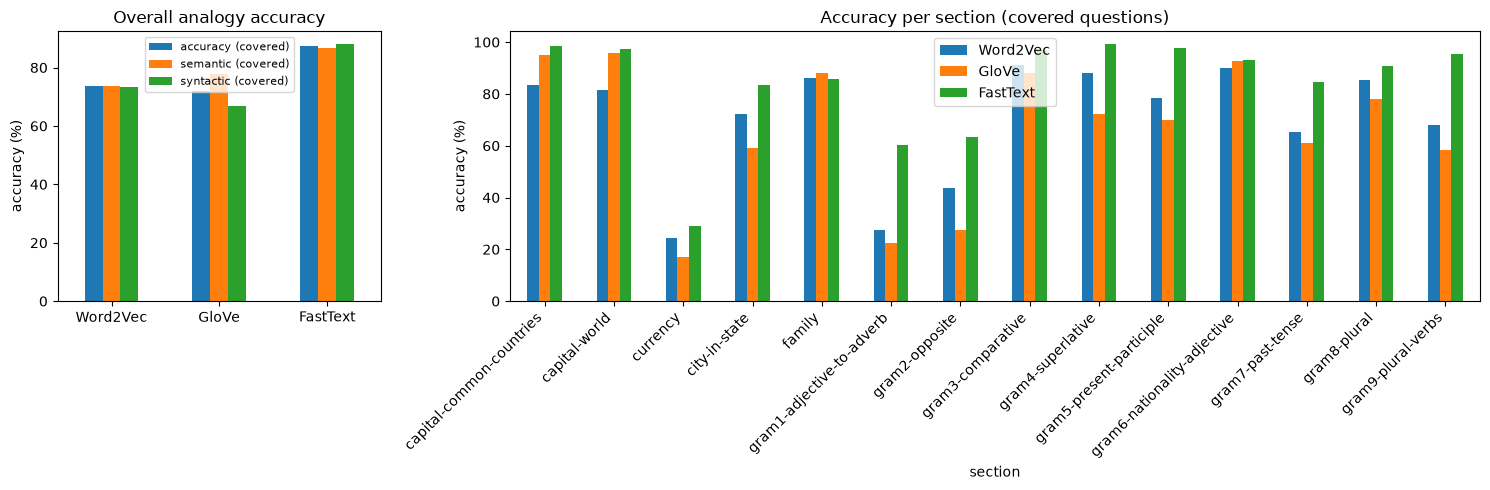

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 3]})
analogy_summary[['accuracy (covered)', 'semantic (covered)', 'syntactic (covered)']].astype(float).mul(100).plot.bar(ax=axes[0], rot=0)
axes[0].set_ylabel('accuracy (%)'); axes[0].set_title('Overall analogy accuracy'); axes[0].legend(fontsize=8)
section_acc.mul(100).plot.bar(ax=axes[1], rot=45)
axes[1].set_ylabel('accuracy (%)'); axes[1].set_title('Accuracy per section (covered questions)')
for lbl in axes[1].get_xticklabels():
    lbl.set_ha('right')
plt.tight_layout(); plt.show()

In [11]:
# Sample errors per model: the same questions, so the models can be compared directly
idx = questions.sample(8, random_state=SEED).index
side = questions.loc[idx, ['section', 'a', 'b', 'c', 'd']].copy()
for m, r in analogy_results.items():
    side[m] = r.loc[idx, 'predicted'].fillna('(not covered)')
side

,section,a,b,c,d,Word2Vec,GloVe,FastText
13845,gram5-present-participle,scream,screaming,describe,describing,describing,describing,describing
16183,gram7-past-tense,hitting,hit,running,ran,run,ran,run
5814,currency,ukraine,hryvnia,argentina,peso,peso,peso,peso
8355,city-in-state,worcester,massachusetts,bakersfield,california,california,california,california
12047,gram4-superlative,big,biggest,hot,hottest,hottest,hottest,hottest
18201,gram8-plural,machine,machines,finger,fingers,fingers,fingers,fingers
4755,capital-world,valletta,malta,caracas,venezuela,venezuela,venezuela,venezuela
12064,gram4-superlative,big,biggest,tasty,tastiest,delicious,delicious,tastiest


**Observations (2.2): comparing the models**

| Model | Accuracy (covered) | Semantic | Syntactic |
|---|---|---|---|
| Word2Vec (Google News, 3M words) | 73.6% | 73.8% | 73.5% |
| GloVe (6B, 400k words) | 72.0% | **78.0%** | 67.0% |
| **FastText (wiki-news, 1M, subword)** | **87.4%** | 86.6% | **88.0%** |

* **FastText is clearly the best** (about 14 points above the other two), and the gap is largest on syntactic questions: `adjective→adverb` 60% vs 27%/23%, `plural-verbs` 96% vs 68%/59%, `superlative` 99% vs 88%/72%. Because its training uses character n-grams, words with the same ending (*-ly*, *-est*, *-s*, *-ing*) get related vectors, which is exactly what these morphological analogies test.
* **GloVe is strong on semantic questions** (capitals 95–96%, family 88%) but weakest on syntactic ones. Its global co-occurrence statistics capture topical/encyclopedic relations well, but it has no morphology.
* **Word2Vec** sits in between. Its Word2Vec and GloVe scores here are close to the published figures (about 74% and 72–75%), which suggests the evaluation code matches the standard method.
* **`currency`** is the hardest section for every model (17–29%). Currency names are rare and ambiguous (*dram*, *real*, *won*).
* Coverage is near-complete for all models (≥ 98.9% of questions), so the accuracy over all questions changes the ranking by less than 1 point.

## Q3. Single-hidden-layer neural network classifier

One network architecture is used for every embedding: `StandardScaler → Dense(300 → 128, ReLU) → softmax(2)`, trained with Adam (scikit-learn `MLPClassifier`). Other settings: L2 `alpha=1e-3`, batch 64, up to 200 epochs, and early stopping on a 10% validation split of the training sample (patience 10). That gives three networks (one per embedding), each trained on (a) mean vectors and (b) TF-IDF-weighted vectors, for six runs on the same 10k/1k split with the same seed. The metric is **macro F1** on the 1,000 test reviews.

In [12]:
def build_network():
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(128,), activation='relu', solver='adam', alpha=1e-3,
                      batch_size=64, learning_rate_init=1e-3, max_iter=200, early_stopping=True,
                      validation_fraction=0.1, n_iter_no_change=10, random_state=SEED))

y_train, y_test = train_df['label'].to_numpy(), test_df['label'].to_numpy()
REPR_NAMES = {'mean': '(a) mean', 'tfidf': '(b) TF-IDF weighted'}
q3_rows, predictions, networks = [], {}, {}
for (label, rep), (X_tr, X_te) in features.items():
    start = time.time()
    net = build_network().fit(X_tr, y_train)
    pred = net.predict(X_te)
    mlp = net[-1]
    predictions[(label, rep)], networks[(label, rep)] = pred, net
    q3_rows.append({'model': label, 'representation': REPR_NAMES[rep],
                    'macro F1': f1_score(y_test, pred, average='macro'),
                    'accuracy': accuracy_score(y_test, pred),
                    'train macro F1': f1_score(y_train, net.predict(X_tr), average='macro'),
                    'best val acc': mlp.best_validation_score_, 'epochs': mlp.n_iter_,
                    'time (s)': round(time.time() - start, 1)})

q3 = pd.DataFrame(q3_rows)
q3.to_csv(OUT / 'q3_results.csv', index=False)
q3.style.format({'macro F1': '{:.4f}', 'accuracy': '{:.4f}', 'train macro F1': '{:.4f}', 'best val acc': '{:.4f}'})

,model,representation,macro F1,accuracy,train macro F1,best val acc,epochs,time (s)
0,Word2Vec,(a) mean,0.8418,0.8420,0.9059,0.8150,16,12.400000
1,Word2Vec,(b) TF-IDF weighted,0.8070,0.8070,0.8824,0.8030,15,11.600000
2,GloVe,(a) mean,0.8010,0.8010,0.8769,0.8070,15,11.800000
3,GloVe,(b) TF-IDF weighted,0.7919,0.7920,0.8646,0.7770,15,8.300000
4,FastText,(a) mean,0.8330,0.8330,0.8392,0.8100,12,4.700000
5,FastText,(b) TF-IDF weighted,0.8249,0.8250,0.8848,0.7940,15,5.800000


representation,(a) mean,(b) TF-IDF weighted,Δ (b − a)
model,,,
Word2Vec,0.8418,0.8070,-0.0348
GloVe,0.8010,0.7919,-0.0091
FastText,0.8330,0.8249,-0.0081


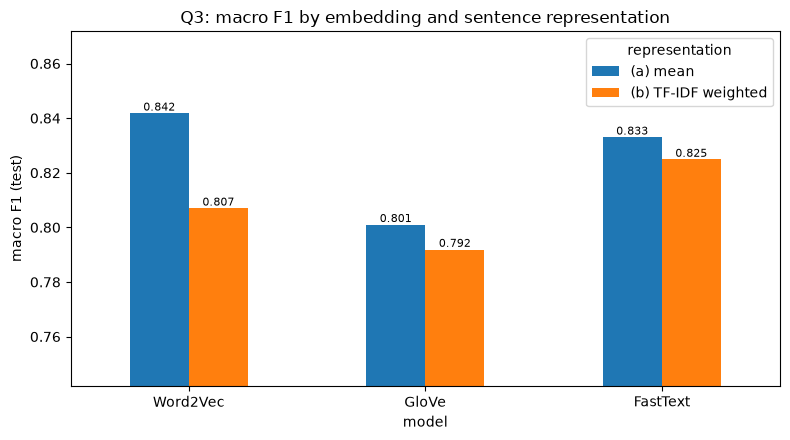

In [13]:
pivot = q3.pivot(index='model', columns='representation', values='macro F1').loc[list(models)]
pivot['Δ (b − a)'] = pivot['(b) TF-IDF weighted'] - pivot['(a) mean']
display(pivot.style.format('{:.4f}'))

ax = pivot[['(a) mean', '(b) TF-IDF weighted']].plot.bar(rot=0, figsize=(8, 4.5))
ax.set_ylabel('macro F1 (test)'); ax.set_title('Q3: macro F1 by embedding and sentence representation')
ax.set_ylim(max(0, pivot.iloc[:, :2].min().min() - 0.05), min(1, pivot.iloc[:, :2].max().max() + 0.03))
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8)
plt.tight_layout(); plt.show()

In [14]:
for (label, rep), pred in predictions.items():
    print(f'=== {label} | {REPR_NAMES[rep]} ===')
    print(classification_report(y_test, pred, target_names=['negative', 'positive'], digits=4))
    print('confusion matrix [rows=true neg/pos]:', confusion_matrix(y_test, pred).tolist(), '\n')

=== Word2Vec | (a) mean ===
              precision    recall  f1-score   support

    negative     0.8685    0.8060    0.8361       500
    positive     0.8190    0.8780    0.8475       500

    accuracy                         0.8420      1000
   macro avg     0.8438    0.8420    0.8418      1000
weighted avg     0.8438    0.8420    0.8418      1000

confusion matrix [rows=true neg/pos]: [[403, 97], [61, 439]] 

=== Word2Vec | (b) TF-IDF weighted ===
              precision    recall  f1-score   support

    negative     0.8052    0.8100    0.8076       500
    positive     0.8089    0.8040    0.8064       500

    accuracy                         0.8070      1000
   macro avg     0.8070    0.8070    0.8070      1000
weighted avg     0.8070    0.8070    0.8070      1000

confusion matrix [rows=true neg/pos]: [[405, 95], [98, 402]] 

=== GloVe | (a) mean ===
              precision    recall  f1-score   support

    negative     0.8065    0.7920    0.7992       500
    positive     0.

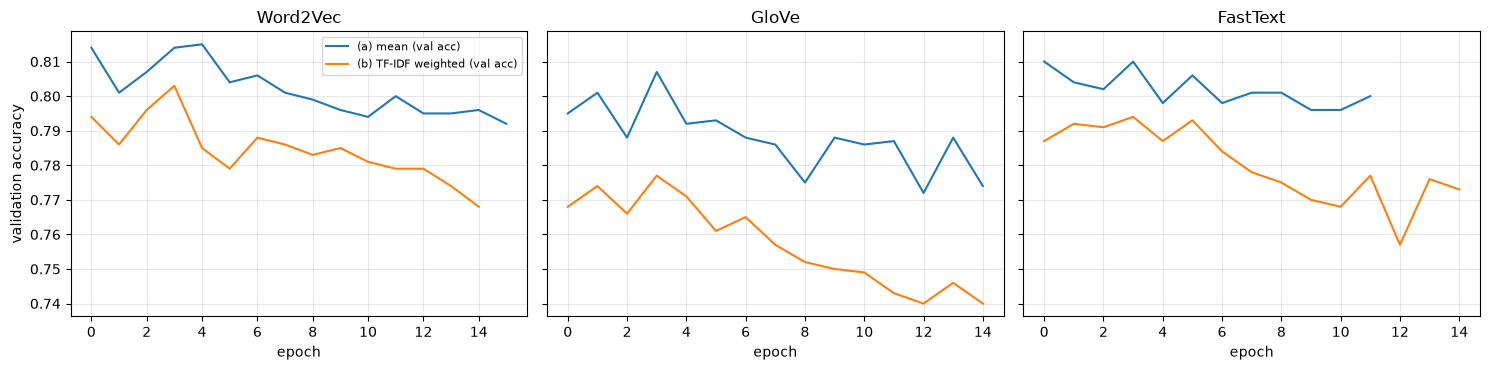

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, label in zip(axes, models):
    for rep in ('mean', 'tfidf'):
        mlp = networks[(label, rep)][-1]
        ax.plot(mlp.validation_scores_, label=f'{REPR_NAMES[rep]} (val acc)')
    ax.set_title(label); ax.set_xlabel('epoch'); ax.grid(alpha=0.3)
axes[0].set_ylabel('validation accuracy'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Robustness check: five random seeds
One train/test split and one weight initialisation can be noisy at this test size (1,000 reviews, so ±1 point of F1 is about 10 reviews). The network is retrained with five seeds (split fixed, initialisation and validation split varied) to check whether the gaps above are larger than the seed noise.

In [16]:
seed_rows = []
for (label, rep), (X_tr, X_te) in features.items():
    for seed in range(5):
        net = build_network().set_params(mlpclassifier__random_state=seed).fit(X_tr, y_train)
        seed_rows.append({'model': label, 'representation': REPR_NAMES[rep], 'seed': seed,
                          'macro F1': f1_score(y_test, net.predict(X_te), average='macro')})
seed_df = pd.DataFrame(seed_rows)
seed_summary = seed_df.groupby(['model', 'representation'])['macro F1'].agg(['mean', 'std', 'min', 'max']).loc[list(models)]
seed_summary.to_csv(OUT / 'q3_seed_summary.csv')
seed_summary.style.format('{:.4f}')


## Conclusions for Q3

**Macro F1 on the 1,000 test reviews** (single run with seed 42, then the mean ± std over 5 seeds):

| Embedding | (a) Mean | (b) TF-IDF weighted | 5-seed mean (a) | 5-seed mean (b) |
|---|---|---|---|---|
| Word2Vec | **0.842** | 0.807 | 0.834 ± 0.009 | 0.807 ± 0.004 |
| GloVe | 0.801 | 0.792 | 0.809 ± 0.004 | 0.790 ± 0.009 |
| FastText | 0.833 | 0.825 | **0.835 ± 0.010** | 0.813 ± 0.011 |

1. **Word2Vec and FastText are tied for best (about 0.835 macro F1); GloVe is about 2.5 points lower.** In the seed-42 run Word2Vec leads (0.842 vs 0.833), but over 5 seeds the gap is 0.001, far smaller than the seed noise, so neither model is clearly better. Word2Vec was trained on news text and FastText's corpus includes news and web text, which are both closer to informal product reviews than GloVe's Wikipedia + Gigaword text. GloVe also loses words: its vocabulary covers the most training words (86% of word types), yet it scores lowest, so vocabulary coverage does not explain the gap.
2. **The simple mean beats the TF-IDF-weighted mean for all three embeddings**, by 2–3 points on average (W2V −2.7, GloVe −1.9, FastText −2.2). That is larger than the seed std, so the effect looks real. TF-IDF gives the largest weights to rare words (product names, typos, words that appear in one review), while sentiment words such as *great*, *bad*, *waste*, *not* and *disappointed* are common across the corpus and get a low IDF. With only 10k documents, IDF estimates are also noisy. For sentiment, then, weighting by "how distinctive is this word" pushes the sentence vector away from the words that carry polarity. TF-IDF weighting tends to help topic classification more than sentiment.
3. **Errors are roughly balanced.** Per-class F1 values are within about 1 point of each other in every run, so macro F1 ≈ accuracy (the test sample is a stratified 50/50 split). Most runs have slightly higher recall on *positive* (e.g., Word2Vec mean: 0.878 positive vs 0.806 negative recall). Negative reviews often quote positive words (*"I expected it to be great, but…"*), and an averaged vector cannot capture that contrast.
4. **The analogy ranking (Q2) does not predict the downstream ranking (Q3).** FastText wins analogies by 14 points but ties Word2Vec on sentiment. Analogy tests measure linear regularities among individual words, while averaged sentence vectors for sentiment depend more on how well the vectors separate positive from negative words and on how well the training domain matches the reviews.
5. **Overfitting is mild.** Training macro F1 is 0.84–0.91 vs 0.79–0.84 test, and early stopping ended training after 12–16 epochs. Averaged embeddings cap performance around 0.83–0.84 because averaging discards word order (e.g., *not good* vs *good*). A sequence model or fine-tuned transformer would be needed to go beyond that.
